
Name - Vanshika Chauhan

Course - B Tech CSE 3rd year

Subject - Computer Vision

CUID - Cu240250953

# Lab Sheet 4: Fourier Transform for Image Filtering



## Setup: Install & Import Required Libraries

Test image shape: (400, 600), dtype: float64, range: [0.00, 1.00]


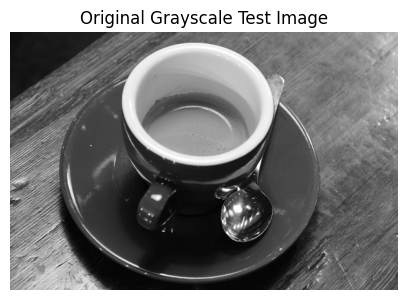

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import ndimage
from skimage import data, color, filters
from skimage.util import random_noise
import warnings
warnings.filterwarnings('ignore')

# Helper: Load a grayscale test image (using skimage built-in)
def load_test_image():
    """Load the built-in camera image as grayscale numpy array (float64, 0-1)."""
    img = color.rgb2gray(data.coffee())  # 400x600 color image → grayscale
    return img
img = load_test_image()
print(f"Test image shape: {img.shape}, dtype: {img.dtype}, range: [{img.min():.2f}, {img.max():.2f}]")
plt.figure(figsize=(5, 4))
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Test Image')
plt.axis('off')
plt.show()

---
## 1: Compute the 2D DFT of an image and visualize both the magnitude spectrum (log-scaled) and the phase spectrum.

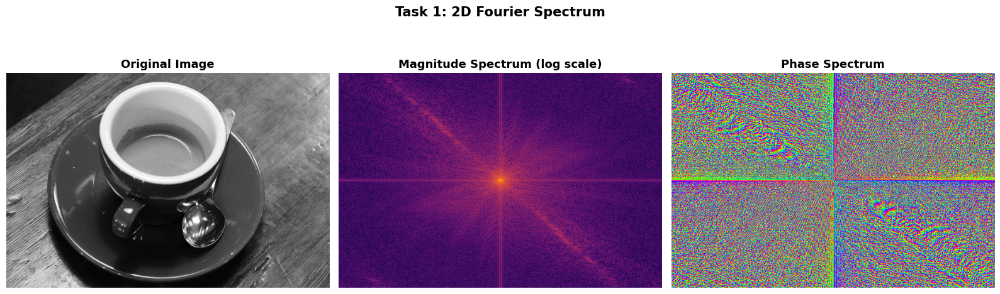

Observations:
- Bright center in magnitude spectrum = low-frequency (smooth) content.
- Outer regions = high-frequency (edge/detail) content.
- Phase encodes the spatial arrangement of structures.


In [ ]:
def compute_fourier_spectrum(image):
    """
    Compute and display the 2D Fourier spectrum (magnitude + phase) of a grayscale image.

    Returns:
        F_shift : shifted 2D FFT (complex array)
        magnitude_spectrum : log-scaled magnitude
        phase_spectrum : phase angle in radians
    """
    # Step 1: Compute 2D FFT
    F = np.fft.fft2(image)

    # Step 2: Shift zero-frequency component to center
    F_shift = np.fft.fftshift(F)

    # Step 3: Compute magnitude spectrum (log scale for visibility)
    magnitude_spectrum = np.log1p(np.abs(F_shift))

    # Step 4: Compute phase spectrum
    phase_spectrum = np.angle(F_shift)

    return F_shift, magnitude_spectrum, phase_spectrum

# Run on test image
F_shift, mag_spec, phase_spec = compute_fourier_spectrum(img)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original Image', fontsize=13, fontweight='bold')
axes[0].axis('off')
axes[1].imshow(mag_spec, cmap='inferno')
axes[1].set_title('Magnitude Spectrum (log scale)', fontsize=13, fontweight='bold')
axes[1].axis('off')
axes[2].imshow(phase_spec, cmap='hsv')
axes[2].set_title('Phase Spectrum', fontsize=13, fontweight='bold')
axes[2].axis('off')
plt.suptitle('Task 1: 2D Fourier Spectrum', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("Observations:")
print("- Bright center in magnitude spectrum = low-frequency (smooth) content.")
print("- Outer regions = high-frequency (edge/detail) content.")
print("- Phase encodes the spatial arrangement of structures.")

---
## 2: Implement three low-pass filters in the frequency domain and compare their blurring effects.

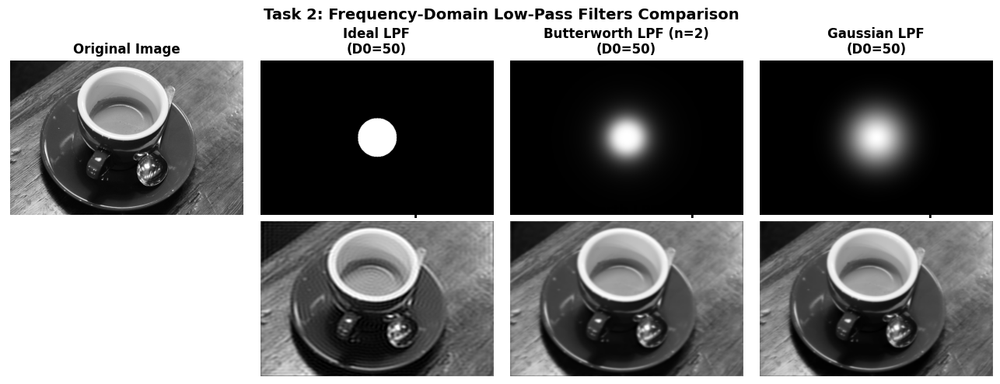

Observations:
- Ideal LPF: Sharp cutoff causes ringing artifacts (Gibbs phenomenon).
- Butterworth LPF: Smooth transition; moderate ringing, controllable via order.
- Gaussian LPF: No ringing; smoothest blur due to Gaussian's own FT being Gaussian.


In [ ]:
def make_distance_matrix(shape):
    """Create a matrix of distances from the center for a given image shape."""
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2
    u = np.arange(rows) - crow
    v = np.arange(cols) - ccol
    V, U = np.meshgrid(v, u)
    D = np.sqrt(U**2 + V**2)
    return D

def ideal_lpf(shape, cutoff):
    """Ideal Low-Pass Filter: 1 inside radius D0, 0 outside."""
    D = make_distance_matrix(shape)
    H = (D <= cutoff).astype(float)
    return H

def butterworth_lpf(shape, cutoff, order=2):
    """Butterworth Low-Pass Filter of given order."""
    D = make_distance_matrix(shape)
    H = 1 / (1 + (D / cutoff) ** (2 * order))
    return H

def gaussian_lpf(shape, cutoff):
    """Gaussian Low-Pass Filter."""
    D = make_distance_matrix(shape)
    H = np.exp(-(D**2) / (2 * (cutoff**2)))
    return H

def apply_frequency_filter(image, H):
    """Apply a frequency-domain filter H to a grayscale image."""
    F = np.fft.fft2(image)
    F_shift = np.fft.fftshift(F)
    G_shift = F_shift * H                    # element-wise multiplication
    G = np.fft.ifftshift(G_shift)
    g = np.real(np.fft.ifft2(G))            # take real part
    g = np.clip(g, 0, 1)                    # clip to valid range
    return g

# Parameters
D0 = 50   # cutoff frequency (radius in pixels)

H_ideal = ideal_lpf(img.shape, D0)
H_butter = butterworth_lpf(img.shape, D0, order=2)
H_gauss = gaussian_lpf(img.shape, D0)

filtered_ideal   = apply_frequency_filter(img, H_ideal)
filtered_butter  = apply_frequency_filter(img, H_butter)
filtered_gauss   = apply_frequency_filter(img, H_gauss)

# Plot results
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
# Row 1: filter shapes
axes[0][0].imshow(img, cmap='gray')
axes[0][0].set_title('Original Image', fontweight='bold')
axes[0][0].axis('off')

for ax, H, title in zip(axes[0][1:], [H_ideal, H_butter, H_gauss],
                         ['Ideal LPF', 'Butterworth LPF (n=2)', 'Gaussian LPF']):
    ax.imshow(H, cmap='gray')
    ax.set_title(f'{title}\n(D0={D0})', fontweight='bold')
    ax.axis('off')
# Row 2: filtered images
axes[1][0].axis('off')
for ax, img_f, title in zip(axes[1][1:],
                              [filtered_ideal, filtered_butter, filtered_gauss],
                              ['Ideal LPF Output', 'Butterworth LPF Output', 'Gaussian LPF Output']):
    ax.imshow(img_f, cmap='gray')
    ax.set_title(title, fontweight='bold')
    ax.axis('off')
plt.suptitle('Task 2: Frequency-Domain Low-Pass Filters Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("Observations:")
print("- Ideal LPF: Sharp cutoff causes ringing artifacts (Gibbs phenomenon).")
print("- Butterworth LPF: Smooth transition; moderate ringing, controllable via order.")
print("- Gaussian LPF: No ringing; smoothest blur due to Gaussian's own FT being Gaussian.")

---
## 3: Enhance edges using a frequency-domain high-pass filter and compare with Sobel/Canny edge detectors.

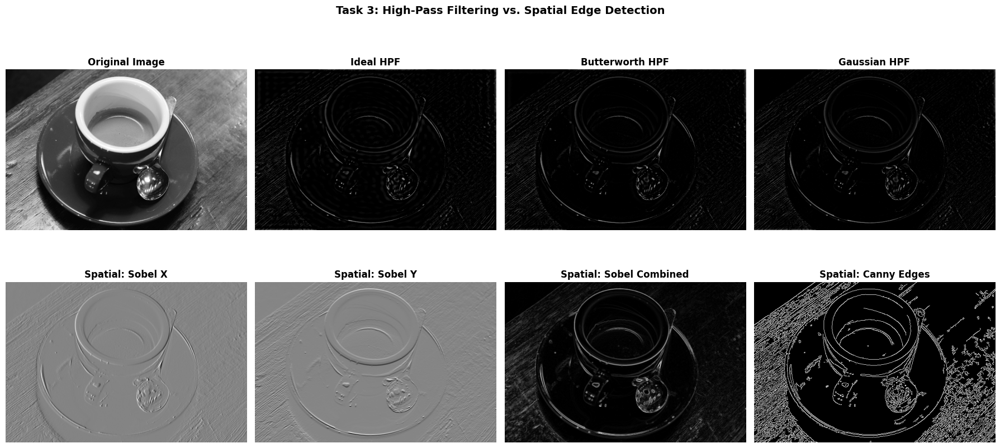

Observations:
- Frequency HPF removes low-frequency background → reveals global edge structure.
- Sobel detects directional gradients; Canny gives clean, thin binary edges.
- Frequency HPF is equivalent to spatial high-pass (sharpening) kernels globally.


In [ ]:
def ideal_hpf(shape, cutoff):
    """Ideal High-Pass Filter = 1 - Ideal LPF."""
    return 1 - ideal_lpf(shape, cutoff)

def butterworth_hpf(shape, cutoff, order=2):
    """Butterworth High-Pass Filter = 1 - Butterworth LPF."""
    return 1 - butterworth_lpf(shape, cutoff, order)

def gaussian_hpf(shape, cutoff):
    """Gaussian High-Pass Filter = 1 - Gaussian LPF."""
    return 1 - gaussian_lpf(shape, cutoff)

D0 = 30  # cutoff
# Frequency-domain HPF outputs
hp_ideal   = apply_frequency_filter(img, ideal_hpf(img.shape, D0))
hp_butter  = apply_frequency_filter(img, butterworth_hpf(img.shape, D0, order=2))
hp_gauss   = apply_frequency_filter(img, gaussian_hpf(img.shape, D0))

# Spatial-domain edge detection
img_uint8 = (img * 255).astype(np.uint8)
sobel_x = cv2.Sobel(img_uint8, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_uint8, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = np.hypot(sobel_x, sobel_y)
sobel_combined = sobel_combined / sobel_combined.max()  # normalize
canny = cv2.Canny(img_uint8, 50, 150) / 255.0

# Plot
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
titles_row1 = ['Original Image', 'Ideal HPF', 'Butterworth HPF', 'Gaussian HPF']
images_row1 = [img, hp_ideal, hp_butter, hp_gauss]
for ax, im, t in zip(axes[0], images_row1, titles_row1):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontweight='bold')
    ax.axis('off')

titles_row2 = ['Sobel X', 'Sobel Y', 'Sobel Combined', 'Canny Edges']
images_row2 = [sobel_x / sobel_x.max(), sobel_y / sobel_y.max(), sobel_combined, canny]
for ax, im, t in zip(axes[1], images_row2, titles_row2):
    ax.imshow(im, cmap='gray')
    ax.set_title(f'Spatial: {t}', fontweight='bold')
    ax.axis('off')

plt.suptitle('Task 3: High-Pass Filtering vs. Spatial Edge Detection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("Observations:")
print("- Frequency HPF removes low-frequency background → reveals global edge structure.")
print("- Sobel detects directional gradients; Canny gives clean, thin binary edges.")
print("- Frequency HPF is equivalent to spatial high-pass (sharpening) kernels globally.")

---
## 4: Add periodic noise to an image, detect noise spikes in the frequency domain, and remove them using a notch filter.

Detected 2 spike location(s) in frequency spectrum.


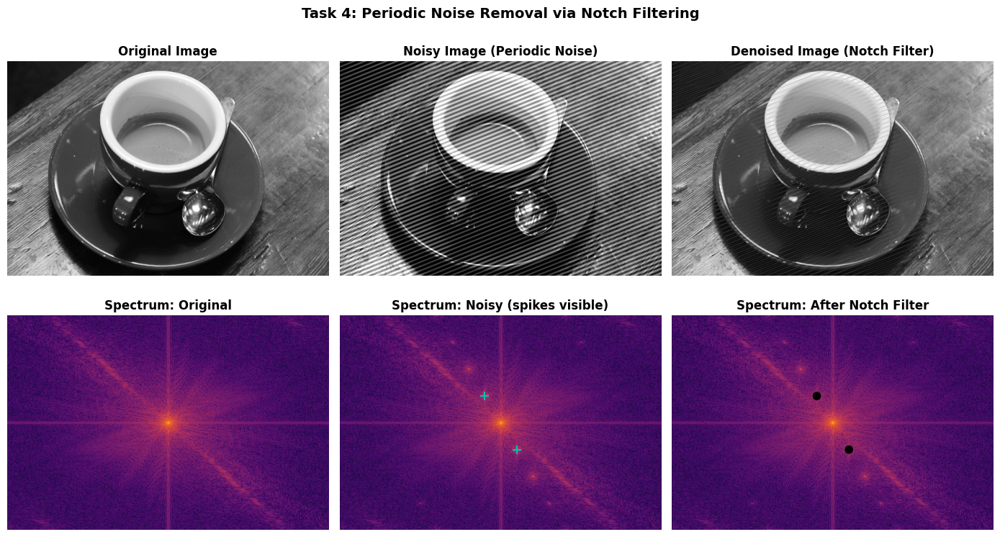

Observations:
- Periodic noise appears as bright symmetric spikes in the frequency spectrum.
- Notch filter zeroes out these spikes, suppressing the noise pattern.
- Denoised image recovers the original structure with reduced periodic artifact.


In [ ]:
def add_periodic_noise(image, freq_x=30, freq_y=50, amplitude=0.3):
    """Add sinusoidal periodic noise to an image."""
    rows, cols = image.shape
    x = np.arange(cols)
    y = np.arange(rows)
    X, Y = np.meshgrid(x, y)
    noise = amplitude * np.sin(2 * np.pi * freq_x * X / cols +
                               2 * np.pi * freq_y * Y / rows)
    noisy = image + noise
    return np.clip(noisy, 0, 1)

def notch_filter(shape, spike_coords, notch_radius=10):
    """
    Create a notch filter that zeroes out circular regions around given spike coordinates.
    spike_coords: list of (row, col) positions of noise spikes in the shifted spectrum.
    """
    rows, cols = shape
    H = np.ones((rows, cols), dtype=float)
    u = np.arange(rows)
    v = np.arange(cols)
    V, U = np.meshgrid(v, u)
    for (r0, c0) in spike_coords:
        D = np.sqrt((U - r0)**2 + (V - c0)**2)
        H[D <= notch_radius] = 0
    return H
def detect_spikes(F_shift, threshold_factor=100):
    """Auto-detect spike locations in the magnitude spectrum (excluding the DC center)."""
    mag = np.abs(F_shift)
    rows, cols = mag.shape
    crow, ccol = rows // 2, cols // 2
    # Mask center DC component
    mask = np.ones_like(mag, dtype=bool)
    mask[crow-10:crow+10, ccol-10:ccol+10] = False
    threshold = np.mean(mag[mask]) * threshold_factor
    spikes = np.argwhere((mag > threshold) & mask)
    return spikes

# Add periodic noise
noisy_img = add_periodic_noise(img, freq_x=30, freq_y=50, amplitude=0.25)
# Compute FFT of noisy image
F_noisy = np.fft.fft2(noisy_img)
F_noisy_shift = np.fft.fftshift(F_noisy)
mag_noisy = np.log1p(np.abs(F_noisy_shift))

# Detect spikes
spikes = detect_spikes(F_noisy_shift, threshold_factor=80)
print(f"Detected {len(spikes)} spike location(s) in frequency spectrum.")

# Create and apply notch filter
H_notch = notch_filter(noisy_img.shape, [tuple(s) for s in spikes], notch_radius=8)
G_shift = F_noisy_shift * H_notch
G = np.fft.ifftshift(G_shift)
denoised_img = np.real(np.fft.ifft2(G))
denoised_img = np.clip(denoised_img, 0, 1)

# Visualize
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0][0].imshow(img, cmap='gray')
axes[0][0].set_title('Original Image', fontweight='bold')
axes[0][0].axis('off')

axes[0][1].imshow(noisy_img, cmap='gray')
axes[0][1].set_title('Noisy Image (Periodic Noise)', fontweight='bold')
axes[0][1].axis('off')

axes[0][2].imshow(denoised_img, cmap='gray')
axes[0][2].set_title('Denoised Image (Notch Filter)', fontweight='bold')
axes[0][2].axis('off')

axes[1][0].imshow(np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(img)))), cmap='inferno')
axes[1][0].set_title('Spectrum: Original', fontweight='bold')
axes[1][0].axis('off')

axes[1][1].imshow(mag_noisy, cmap='inferno')
axes[1][1].set_title('Spectrum: Noisy (spikes visible)', fontweight='bold')
# Mark detected spikes
for s in spikes[:20]:   # limit markers
    axes[1][1].plot(s[1], s[0], 'c+', markersize=8, markeredgewidth=1.5)
axes[1][1].axis('off')

axes[1][2].imshow(np.log1p(np.abs(G_shift)), cmap='inferno')
axes[1][2].set_title('Spectrum: After Notch Filter', fontweight='bold')
axes[1][2].axis('off')

plt.suptitle('Task 4: Periodic Noise Removal via Notch Filtering', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observations:")
print("- Periodic noise appears as bright symmetric spikes in the frequency spectrum.")
print("- Notch filter zeroes out these spikes, suppressing the noise pattern.")
print("- Denoised image recovers the original structure with reduced periodic artifact.")

---
## 5: Compress an image by keeping only the top-k largest Fourier coefficients (by magnitude) and reconstruct the image. Compare PSNR at different k values.

k=    100 | Compression ratio:   0.04% | PSNR: 17.98 dB
k=    500 | Compression ratio:   0.21% | PSNR: 20.70 dB
k=   2000 | Compression ratio:   0.83% | PSNR: 23.17 dB
k=   5000 | Compression ratio:   2.08% | PSNR: 24.78 dB
k=  20000 | Compression ratio:   8.33% | PSNR: 28.26 dB
k= 240000 | Compression ratio: 100.00% | PSNR: 316.67 dB


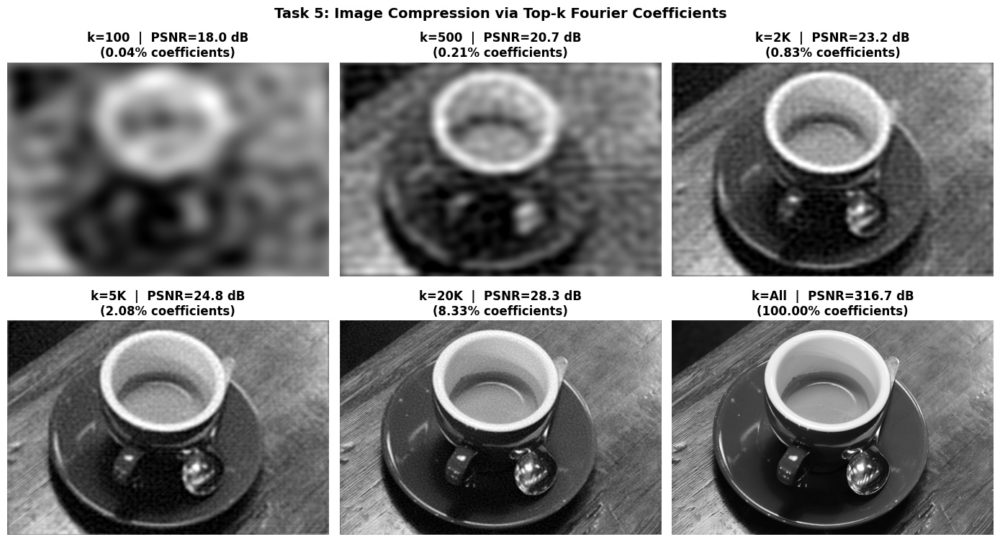

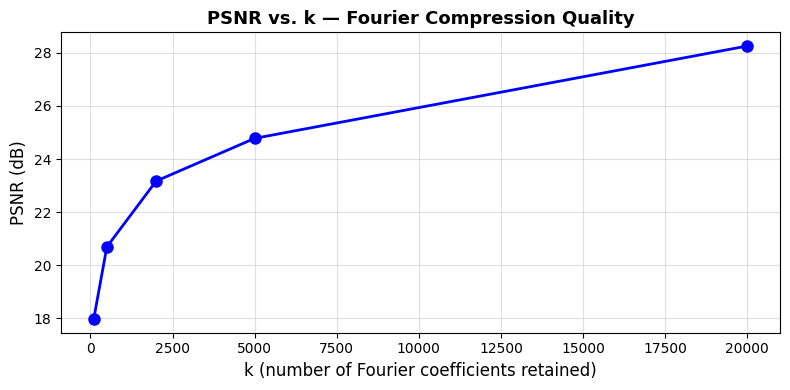

Observations:
- Very few coefficients (k=100) retain only the dominant low-frequency structure.
- PSNR increases rapidly with k — most energy is concentrated in a few coefficients.
- This is the basis of JPEG compression (DCT-based, similar concept).


In [ ]:
def compress_with_topk_fft(image, k):
    """
    Compress image by keeping only top-k Fourier coefficients.

    Args:
        image : 2D grayscale image (float64, 0-1)
        k     : number of Fourier coefficients to retain

    Returns:
        reconstructed : reconstructed image (clipped to [0,1])
        compression_ratio : k / total_coefficients
    """
    F = np.fft.fft2(image)
    total = F.size

    # Flatten, find top-k indices by magnitude
    F_flat = F.flatten()
    magnitudes = np.abs(F_flat)
    top_k_indices = np.argsort(magnitudes)[::-1][:k]

    # Zero out all but top-k
    F_compressed = np.zeros_like(F_flat)
    F_compressed[top_k_indices] = F_flat[top_k_indices]
    F_compressed = F_compressed.reshape(F.shape)

    # Reconstruct
    reconstructed = np.real(np.fft.ifft2(F_compressed))
    reconstructed = np.clip(reconstructed, 0, 1)
    compression_ratio = k / total

    return reconstructed, compression_ratio

def psnr(original, reconstructed):
    """Peak Signal-to-Noise Ratio (dB). Higher = better quality."""
    mse = np.mean((original - reconstructed) ** 2)
    if mse == 0:
        return float('inf')
    return 10 * np.log10(1.0 / mse)

# Test multiple k values
total_coeffs = img.size
k_values = [100, 500, 2000, 5000, 20000, total_coeffs]
labels    = ['k=100', 'k=500', 'k=2K', 'k=5K', 'k=20K', 'k=All']

results = []
psnr_vals = []
for k in k_values:
    recon, ratio = compress_with_topk_fft(img, k)
    p = psnr(img, recon)
    results.append(recon)
    psnr_vals.append(p)
    print(f"k={k:>7} | Compression ratio: {ratio*100:6.2f}% | PSNR: {p:.2f} dB")

# Plot
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, recon, label, p, k in zip(axes.flat, results, labels, psnr_vals, k_values):
    ax.imshow(recon, cmap='gray')
    ax.set_title(f'{label}  |  PSNR={p:.1f} dB\n({k/total_coeffs*100:.2f}% coefficients)', fontweight='bold')
    ax.axis('off')

plt.suptitle('Task 5: Image Compression via Top-k Fourier Coefficients', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# PSNR vs k plot
plt.figure(figsize=(8, 4))
plt.plot(k_values[:-1], psnr_vals[:-1], 'bo-', linewidth=2, markersize=8)
plt.xlabel('k (number of Fourier coefficients retained)', fontsize=12)
plt.ylabel('PSNR (dB)', fontsize=12)
plt.title('PSNR vs. k — Fourier Compression Quality', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

print("Observations:")
print("- Very few coefficients (k=100) retain only the dominant low-frequency structure.")
print("- PSNR increases rapidly with k — most energy is concentrated in a few coefficients.")
print("- This is the basis of JPEG compression (DCT-based, similar concept).")

---
## 6: Embed an invisible watermark into an image by modifying specific frequency components, and then extract/reveal it using the same technique.

Watermarked image PSNR vs original: 17.77 dB


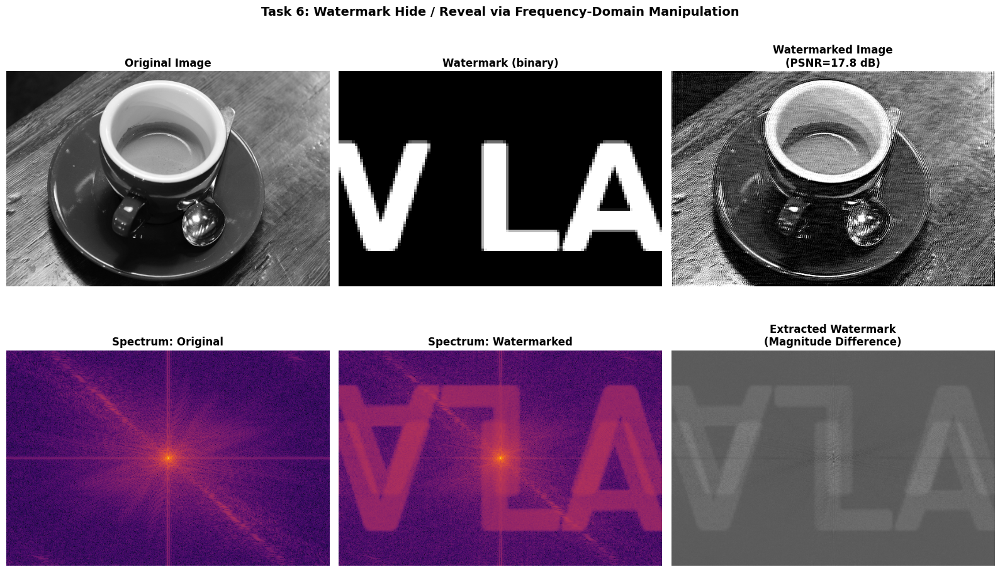

Observations:
- The watermark is embedded in the frequency magnitude — invisible to the human eye.
- Higher alpha makes extraction easier but degrades image quality (lower PSNR).
- Extraction relies on the original DFT (non-blind) or statistical difference (blind).
- This technique is related to digital steganography and DWT-based watermarking.


In [ ]:
def create_text_watermark(shape, text='WM', scale=0.15):
    """
    Create a simple binary watermark image with text using OpenCV.
    Resized to `scale` fraction of the host image shape.
    """
    h = max(32, int(shape[0] * scale))
    w = max(64, int(shape[1] * scale))
    wm = np.zeros((h, w), dtype=np.uint8)
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = h / 40
    thickness = max(1, int(h / 20))
    text_size = cv2.getTextSize(text, font, font_scale, thickness)[0]
    x = (w - text_size[0]) // 2
    y = (h + text_size[1]) // 2
    cv2.putText(wm, text, (x, y), font, font_scale, 255, thickness)
    return wm.astype(float) / 255.0

def embed_watermark(host_image, watermark, alpha=5.0):
    """
    Embed a watermark in the frequency domain by modifying the DFT magnitude.

    Strategy:
      1. Compute DFT of host image.
      2. Resize watermark to match host DFT shape.
      3. Add scaled watermark to the magnitude of the shifted spectrum.
      4. Reconstruct image with IDFT.

    Args:
        host_image : 2D grayscale host image (float64)
        watermark  : 2D binary watermark image
        alpha      : embedding strength (higher = more visible but more distortion)

    Returns:
        watermarked : host image with embedded watermark (clipped to [0,1])
        F_shift     : shifted DFT of original (for extraction key)
    """
    rows, cols = host_image.shape

    # Resize watermark to host size
    wm_resized = cv2.resize(watermark, (cols, rows), interpolation=cv2.INTER_LINEAR)

    # DFT of host
    F = np.fft.fft2(host_image)
    F_shift = np.fft.fftshift(F)

    # Modify magnitude: add watermark scaled by alpha
    magnitude = np.abs(F_shift)
    phase     = np.angle(F_shift)
    magnitude_wm = magnitude + alpha * wm_resized * magnitude.mean()

    # Reconstruct complex spectrum with modified magnitude
    F_shift_wm = magnitude_wm * np.exp(1j * phase)
    F_wm = np.fft.ifftshift(F_shift_wm)
    watermarked = np.real(np.fft.ifft2(F_wm))
    watermarked = np.clip(watermarked, 0, 1)

    return watermarked, F_shift

def extract_watermark(watermarked_image, original_F_shift=None):
    """
    Extract the watermark from a watermarked image.

    If the original DFT (F_shift) is available (non-blind extraction):
      Watermark ≈ (|F_wm_shift| - |F_shift|) / (alpha * mean_magnitude)

    If not available (blind extraction):
      Show the difference in magnitude spectra directly.
    """
    F_wm = np.fft.fft2(watermarked_image)
    F_wm_shift = np.fft.fftshift(F_wm)
    mag_wm = np.abs(F_wm_shift)

    if original_F_shift is not None:
        mag_orig = np.abs(original_F_shift)
        diff = (mag_wm - mag_orig)
        diff = diff - diff.min()
        if diff.max() > 0:
            diff /= diff.max()
        return diff
    else:
        return mag_wm / mag_wm.max()

# Create watermark
watermark = create_text_watermark(img.shape, text='CV LAB', scale=0.2)

# Embed
watermarked_img, F_orig_shift = embed_watermark(img, watermark, alpha=8.0)

# Extract
extracted_wm = extract_watermark(watermarked_img, F_orig_shift)

# Compute PSNR of watermarked vs original
p = psnr(img, watermarked_img)
print(f"Watermarked image PSNR vs original: {p:.2f} dB")

# Visualize
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes[0][0].imshow(img, cmap='gray')
axes[0][0].set_title('Original Image', fontweight='bold')
axes[0][0].axis('off')

axes[0][1].imshow(watermark, cmap='gray')
axes[0][1].set_title('Watermark (binary)', fontweight='bold')
axes[0][1].axis('off')

axes[0][2].imshow(watermarked_img, cmap='gray')
axes[0][2].set_title(f'Watermarked Image\n(PSNR={p:.1f} dB)', fontweight='bold')
axes[0][2].axis('off')

axes[1][0].imshow(np.log1p(np.abs(F_orig_shift)), cmap='inferno')
axes[1][0].set_title('Spectrum: Original', fontweight='bold')
axes[1][0].axis('off')

axes[1][1].imshow(np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(watermarked_img)))), cmap='inferno')
axes[1][1].set_title('Spectrum: Watermarked', fontweight='bold')
axes[1][1].axis('off')

axes[1][2].imshow(extracted_wm, cmap='gray')
axes[1][2].set_title('Extracted Watermark\n(Magnitude Difference)', fontweight='bold')
axes[1][2].axis('off')

plt.suptitle('Task 6: Watermark Hide / Reveal via Frequency-Domain Manipulation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observations:")
print("- The watermark is embedded in the frequency magnitude — invisible to the human eye.")
print("- Higher alpha makes extraction easier but degrades image quality (lower PSNR).")
print("- Extraction relies on the original DFT (non-blind) or statistical difference (blind).")
print("- This technique is related to digital steganography and DWT-based watermarking.")

---
## Build a filter that isolates (band-pass) or suppresses (band-reject) a specific frequency range in a textured image.

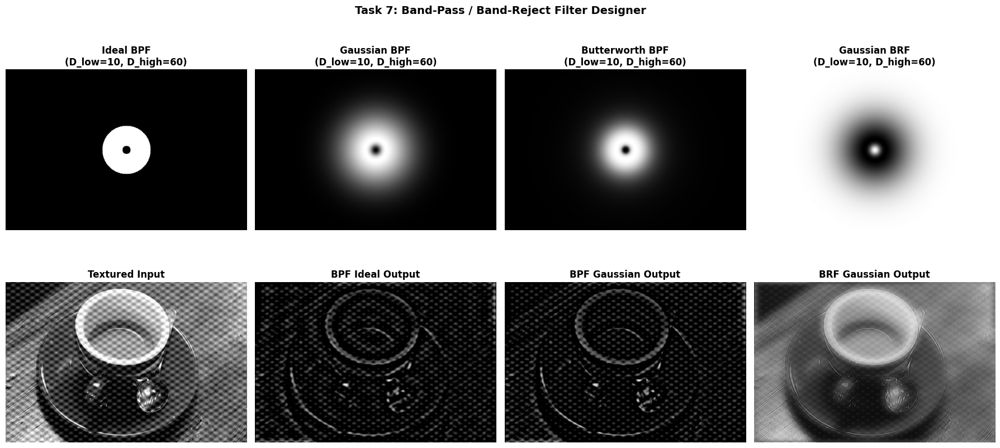

Observations:
- Band-Pass Filter: retains only the texture frequencies (mid-range) — isolates texture.
- Band-Reject Filter: removes that frequency band — smooths out the texture.
- Ideal BPF shows ringing; Gaussian BPF gives smooth, artifact-free isolation.


In [ ]:
def band_pass_filter(shape, low_cutoff, high_cutoff, filter_type='gaussian'):
    """
    Band-Pass Filter: passes frequencies between low_cutoff and high_cutoff.
    filter_type: 'ideal' | 'gaussian' | 'butterworth'
    """
    if filter_type == 'ideal':
        H_lp = ideal_lpf(shape, high_cutoff)
        H_hp = ideal_hpf(shape, low_cutoff)
    elif filter_type == 'gaussian':
        H_lp = gaussian_lpf(shape, high_cutoff)
        H_hp = gaussian_hpf(shape, low_cutoff)
    else:  # butterworth
        H_lp = butterworth_lpf(shape, high_cutoff, order=2)
        H_hp = butterworth_hpf(shape, low_cutoff, order=2)
    return H_lp * H_hp   # AND of LPF and HPF

def band_reject_filter(shape, low_cutoff, high_cutoff, filter_type='gaussian'):
    """Band-Reject (Notch) Filter: rejects frequencies between low_cutoff and high_cutoff."""
    return 1 - band_pass_filter(shape, low_cutoff, high_cutoff, filter_type)

# Create a textured test image (checkerboard + smooth image)
def make_textured_image(base_image, texture_freq=20, texture_amp=0.15):
    """Add a regular texture (mid-frequency sinusoid) to a base image."""
    rows, cols = base_image.shape
    x = np.arange(cols)
    y = np.arange(rows)
    X, Y = np.meshgrid(x, y)
    texture = texture_amp * np.sin(2 * np.pi * texture_freq * X / cols) * \
                             np.cos(2 * np.pi * texture_freq * Y / rows)
    return np.clip(base_image + texture, 0, 1)


textured_img = make_textured_image(img, texture_freq=25, texture_amp=0.2)

# Filter parameters
D_low, D_high = 10, 60   # band: 10-60 cycles

H_bp_ideal   = band_pass_filter(textured_img.shape, D_low, D_high, 'ideal')
H_bp_gauss   = band_pass_filter(textured_img.shape, D_low, D_high, 'gaussian')
H_bp_butter  = band_pass_filter(textured_img.shape, D_low, D_high, 'butterworth')
H_br_gauss   = band_reject_filter(textured_img.shape, D_low, D_high, 'gaussian')
bp_ideal  = apply_frequency_filter(textured_img, H_bp_ideal)
bp_gauss  = apply_frequency_filter(textured_img, H_bp_gauss)
bp_butter = apply_frequency_filter(textured_img, H_bp_butter)
br_gauss  = apply_frequency_filter(textured_img, H_br_gauss)

# Visualize filter shapes
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Row 1: filter masks
for ax, H, title in zip(axes[0],
    [H_bp_ideal, H_bp_gauss, H_bp_butter, H_br_gauss],
    ['Ideal BPF', 'Gaussian BPF', 'Butterworth BPF', 'Gaussian BRF']):
    ax.imshow(H, cmap='gray')
    ax.set_title(f'{title}\n(D_low={D_low}, D_high={D_high})', fontweight='bold')
    ax.axis('off')

# Row 2: results
images_r2 = [textured_img, bp_ideal, bp_gauss, br_gauss]
titles_r2 = ['Textured Input', 'BPF Ideal Output', 'BPF Gaussian Output', 'BRF Gaussian Output']
for ax, im, t in zip(axes[1], images_r2, titles_r2):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontweight='bold')
    ax.axis('off')

plt.suptitle('Task 7: Band-Pass / Band-Reject Filter Designer', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print('Observations:')
print('- Band-Pass Filter: retains only the texture frequencies (mid-range) — isolates texture.')
print('- Band-Reject Filter: removes that frequency band — smooths out the texture.')
print('- Ideal BPF shows ringing; Gaussian BPF gives smooth, artifact-free isolation.')

---
## 8: Swap the phase and magnitude components between two images to reveal their relative importance in reconstructing recognizable content.

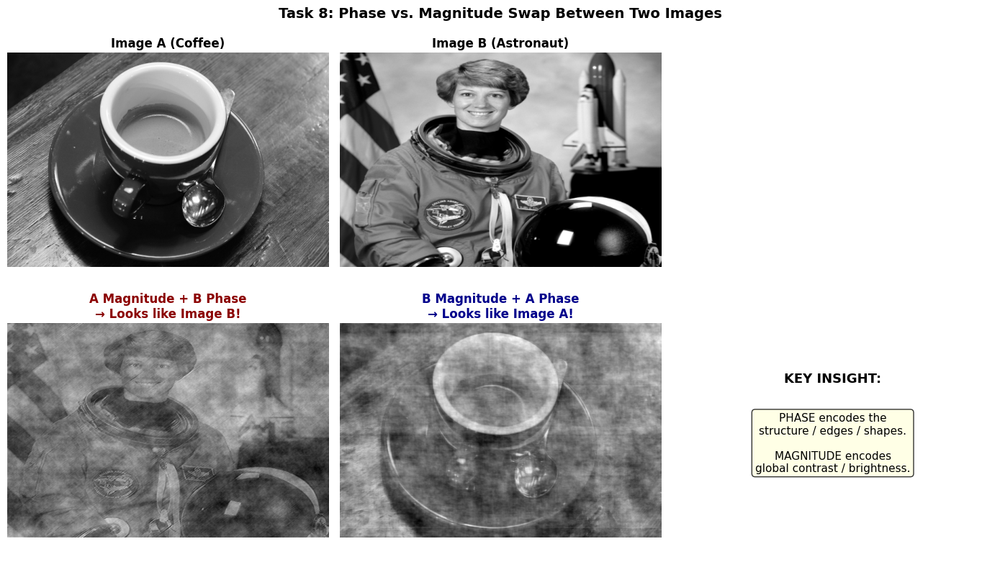

Observations:
- The reconstructed image resembles whichever image contributed the PHASE.
- Phase carries structural/edge information (more perceptually important).
- Magnitude governs overall brightness distribution but NOT the recognizable structure.


In [ ]:
def swap_phase_magnitude(image_A, image_B):
    """
    Swap phase and magnitude between two images.

    Returns:
        A_mag_B_phase : image with A's magnitude + B's phase
        B_mag_A_phase : image with B's magnitude + A's phase
    """
    # Compute FFTs
    FA = np.fft.fft2(image_A)
    FB = np.fft.fft2(image_B)

    # Extract components
    mag_A, phase_A = np.abs(FA), np.angle(FA)
    mag_B, phase_B = np.abs(FB), np.angle(FB)

    # Recombine: A's magnitude with B's phase
    F_A_mag_B_phase = mag_A * np.exp(1j * phase_B)
    recon_A_mag_B_phase = np.real(np.fft.ifft2(F_A_mag_B_phase))

    # Recombine: B's magnitude with A's phase
    F_B_mag_A_phase = mag_B * np.exp(1j * phase_A)
    recon_B_mag_A_phase = np.real(np.fft.ifft2(F_B_mag_A_phase))

    # Normalize each to [0, 1]
    def normalize(x):
        x = x - x.min()
        return x / x.max() if x.max() > 0 else x

    return normalize(recon_A_mag_B_phase), normalize(recon_B_mag_A_phase)


# Use two different built-in images
from skimage import data as skdata
img_A = color.rgb2gray(skdata.coffee())          # coffee cup
img_B = color.rgb2gray(skdata.astronaut())        # astronaut face

# Resize B to match A
img_B_resized = cv2.resize(img_B, (img_A.shape[1], img_A.shape[0]))

recon_AmBp, recon_BmAp = swap_phase_magnitude(img_A, img_B_resized)

# Plot
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0][0].imshow(img_A, cmap='gray')
axes[0][0].set_title('Image A (Coffee)', fontweight='bold')
axes[0][0].axis('off')

axes[0][1].imshow(img_B_resized, cmap='gray')
axes[0][1].set_title('Image B (Astronaut)', fontweight='bold')
axes[0][1].axis('off')

axes[0][2].axis('off')  # spacer

axes[1][0].imshow(recon_AmBp, cmap='gray')
axes[1][0].set_title('A Magnitude + B Phase\n→ Looks like Image B!', fontweight='bold', color='darkred')
axes[1][0].axis('off')
axes[1][1].imshow(recon_BmAp, cmap='gray')
axes[1][1].set_title('B Magnitude + A Phase\n→ Looks like Image A!', fontweight='bold', color='darkblue')
axes[1][1].axis('off')

# Visual explanation diagram
axes[1][2].text(0.5, 0.7, 'KEY INSIGHT:', ha='center', va='center',
                fontsize=13, fontweight='bold', transform=axes[1][2].transAxes)
axes[1][2].text(0.5, 0.45,
    'PHASE encodes the\nstructure / edges / shapes.\n\nMAGNITUDE encodes\nglobal contrast / brightness.',
    ha='center', va='center', fontsize=11, transform=axes[1][2].transAxes,
    bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
axes[1][2].axis('off')

plt.suptitle('Task 8: Phase vs. Magnitude Swap Between Two Images', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Observations:')
print('- The reconstructed image resembles whichever image contributed the PHASE.')
print('- Phase carries structural/edge information (more perceptually important).')
print('- Magnitude governs overall brightness distribution but NOT the recognizable structure.')

---
## 9: Flag blurry images by measuring the high-frequency energy content of their Fourier spectrum. Blurry images have significantly less high-frequency energy.

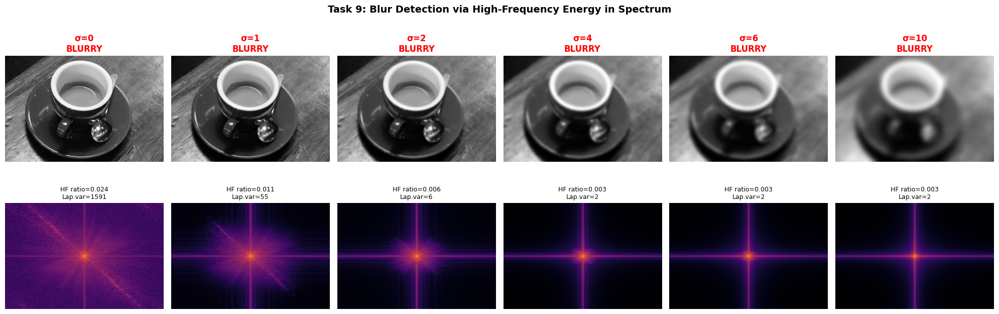

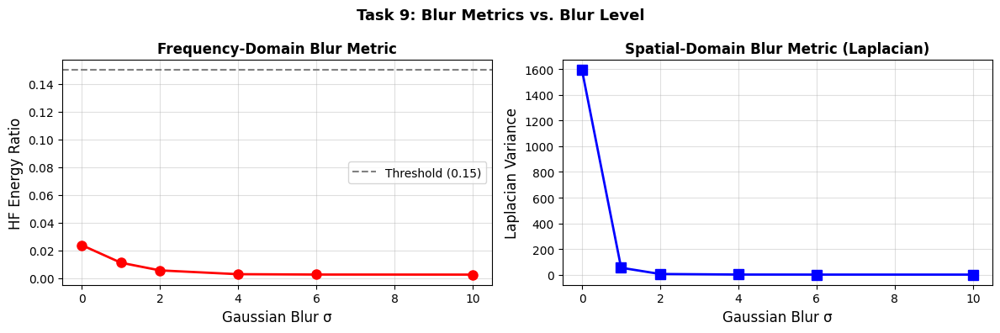

Summary Table:
Sigma    HF Ratio     Lap.Var      Verdict
---------------------------------------------
0        0.0238       1590.9       BLURRY
1        0.0111       55.1         BLURRY
2        0.0056       6.4          BLURRY
4        0.0028       2.1          BLURRY
6        0.0026       1.7          BLURRY
10       0.0025       1.6          BLURRY

Observations:
- Both HF energy ratio and Laplacian variance drop sharply with blur.
- Spectrum of blurry images shows energy concentrated near center (low frequency).
- A threshold on HF ratio (e.g., 0.15) can automatically classify blur.


In [ ]:
def compute_hf_energy_ratio(image, hf_cutoff=30):
    """
    Compute the ratio of high-frequency energy to total energy in the Fourier spectrum.
    Low ratio → blurry image.  High ratio → sharp image.

    Args:
        image     : 2D grayscale image (float64)
        hf_cutoff : frequency radius separating LF and HF regions

    Returns:
        hf_ratio  : float in [0, 1]
        verdict   : 'BLURRY' or 'SHARP'
    """
    F = np.fft.fft2(image)
    F_shift = np.fft.fftshift(F)
    power = np.abs(F_shift) ** 2   # power spectrum

    D = make_distance_matrix(image.shape)
    hf_mask = D > hf_cutoff

    total_energy = power.sum()
    hf_energy    = power[hf_mask].sum()
    hf_ratio     = hf_energy / total_energy if total_energy > 0 else 0

    return hf_ratio, ('SHARP' if hf_ratio > 0.15 else 'BLURRY')


def laplacian_variance(image):
    """Classic Laplacian-variance blur metric (spatial domain). High = sharp."""
    img_uint8 = (image * 255).astype(np.uint8)
    lap = cv2.Laplacian(img_uint8, cv2.CV_64F)
    return lap.var()
# Generate test images with increasing blur levels
sigma_levels = [0, 1, 2, 4, 6, 10]
blurred_images = []
for sigma in sigma_levels:
    if sigma == 0:
        blurred_images.append(img.copy())
    else:
        blurred = filters.gaussian(img, sigma=sigma)
        blurred_images.append(blurred)

# Compute metrics
hf_ratios   = []
lap_vars    = []
verdicts    = []
for bimg in blurred_images:
    ratio, verdict = compute_hf_energy_ratio(bimg, hf_cutoff=30)
    lv = laplacian_variance(bimg)
    hf_ratios.append(ratio)
    lap_vars.append(lv)
    verdicts.append(verdict)

# Plot images + metrics
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for i, (bimg, sigma, ratio, lv, verdict) in enumerate(
        zip(blurred_images, sigma_levels, hf_ratios, lap_vars, verdicts)):
    color_v = 'green' if verdict == 'SHARP' else 'red'
    axes[0][i].imshow(bimg, cmap='gray')
    axes[0][i].set_title(f'σ={sigma}\n{verdict}', fontweight='bold', color=color_v)
    axes[0][i].axis('off')

    axes[1][i].imshow(np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(bimg)))), cmap='inferno')
    axes[1][i].set_title(f'HF ratio={ratio:.3f}\nLap.var={lv:.0f}', fontsize=9)
    axes[1][i].axis('off')

plt.suptitle('Task 9: Blur Detection via High-Frequency Energy in Spectrum', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
# Metric comparison plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(sigma_levels, hf_ratios, 'ro-', linewidth=2, markersize=8)
ax1.axhline(0.15, color='gray', linestyle='--', label='Threshold (0.15)')
ax1.set_xlabel('Gaussian Blur σ', fontsize=12)
ax1.set_ylabel('HF Energy Ratio', fontsize=12)
ax1.set_title('Frequency-Domain Blur Metric', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.4)

ax2.plot(sigma_levels, lap_vars, 'bs-', linewidth=2, markersize=8)
ax2.set_xlabel('Gaussian Blur σ', fontsize=12)
ax2.set_ylabel('Laplacian Variance', fontsize=12)
ax2.set_title('Spatial-Domain Blur Metric (Laplacian)', fontweight='bold')
ax2.grid(True, alpha=0.4)

plt.suptitle('Task 9: Blur Metrics vs. Blur Level', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Summary Table:')
print(f'{"Sigma":<8} {"HF Ratio":<12} {"Lap.Var":<12} {"Verdict"}')
print('-' * 45)
for s, r, lv, v in zip(sigma_levels, hf_ratios, lap_vars, verdicts):
    print(f'{s:<8} {r:<12.4f} {lv:<12.1f} {v}')

print('\nObservations:')
print('- Both HF energy ratio and Laplacian variance drop sharply with blur.')
print('- Spectrum of blurry images shows energy concentrated near center (low frequency).')
print('- A threshold on HF ratio (e.g., 0.15) can automatically classify blur.')

---
##10:  Build a comprehensive comparison dashboard showing spatial-domain and frequency-domain filtering results side by side for the same image.

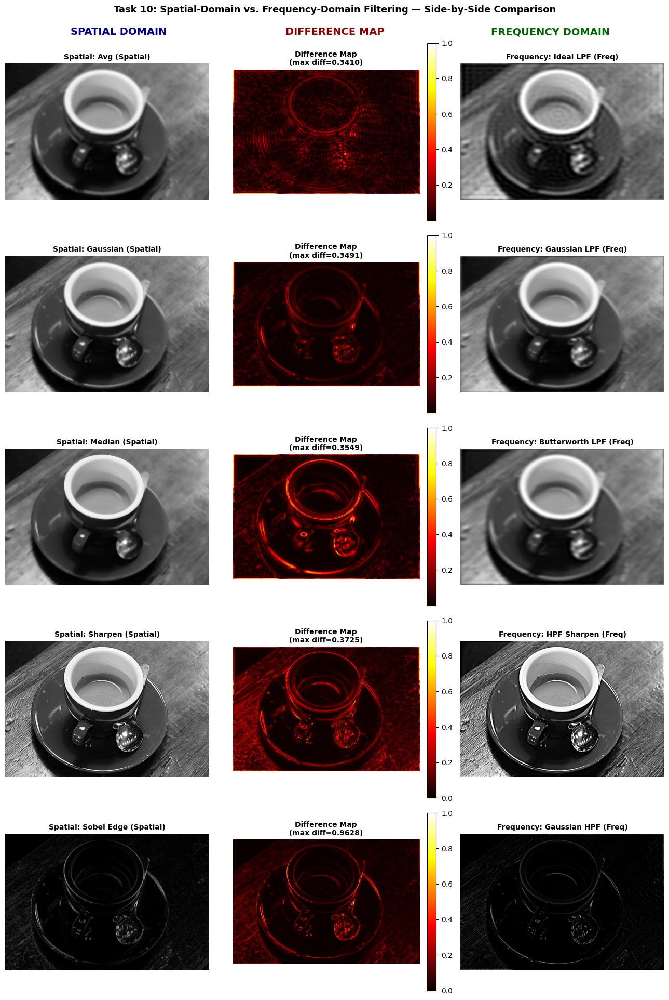

Side-by-Side Summary:
Filter Type               Spatial                        Frequency Equivalent
---------------------------------------------------------------------------
Low-Pass Blur             Avg (Spatial)                  Ideal LPF (Freq)
Gaussian Blur             Gaussian (Spatial)             Gaussian LPF (Freq)
Smooth Filtering          Median (Spatial)               Butterworth LPF (Freq)
Sharpening / HFE          Sharpen (Spatial)              HPF Sharpen (Freq)
Edge Enhancement          Sobel Edge (Spatial)           Gaussian HPF (Freq)

Observations:
- Spatial Gaussian blur ≡ Frequency Gaussian LPF (mathematically identical).
- Ideal LPF has no clean spatial equivalent — causes ringing (Gibbs phenomenon).
- Frequency domain is more efficient for large kernels (FFT is O(N log N)).
- Spatial domain is intuitive; frequency domain offers global frequency control.


In [ ]:
def spatial_domain_filters(image):
    """Apply common spatial-domain filters and return results dict."""
    img_uint8 = (image * 255).astype(np.uint8)
    results = {}

    # Blurring
    results['Avg (Spatial)']      = cv2.blur(img_uint8, (9, 9)).astype(float) / 255
    results['Gaussian (Spatial)'] = cv2.GaussianBlur(img_uint8, (9, 9), 0).astype(float) / 255
    results['Median (Spatial)']   = cv2.medianBlur(img_uint8, 9).astype(float) / 255

    # Sharpening (unsharp mask)
    blurred = cv2.GaussianBlur(img_uint8, (9, 9), 0)
    sharpened = cv2.addWeighted(img_uint8, 1.8, blurred, -0.8, 0)
    results['Sharpen (Spatial)']  = np.clip(sharpened, 0, 255).astype(float) / 255

    # Edge detection
    sobel = cv2.Sobel(img_uint8, cv2.CV_64F, 1, 0, ksize=3)
    sobel = np.abs(sobel)
    results['Sobel Edge (Spatial)'] = sobel / sobel.max()

    return results

def frequency_domain_filters(image):
    """Apply equivalent frequency-domain filters and return results dict."""
    results = {}
    shape = image.shape
    # Blurring equivalents (LPF)
    results['Ideal LPF (Freq)']      = apply_frequency_filter(image, ideal_lpf(shape, 30))
    results['Gaussian LPF (Freq)']   = apply_frequency_filter(image, gaussian_lpf(shape, 30))
    # Median has no direct freq equivalent — use Butterworth as closest
    results['Butterworth LPF (Freq)'] = apply_frequency_filter(image, butterworth_lpf(shape, 30, order=3))
    # Sharpening (HPF boost)
    H_hp = gaussian_hpf(shape, 30)
    H_sharp = 1 + 1.5 * H_hp   # high-frequency emphasis
    sharpened_freq = apply_frequency_filter(image, H_sharp)
    results['HPF Sharpen (Freq)']    = np.clip(sharpened_freq, 0, 1)

    # Edge (HPF)
    results['Gaussian HPF (Freq)']   = apply_frequency_filter(image, gaussian_hpf(shape, 30))

    return results
# Get all results
spatial_results = spatial_domain_filters(img)
freq_results    = frequency_domain_filters(img)

filter_pairs = [
    ('Avg (Spatial)',          'Ideal LPF (Freq)',         'Low-Pass Blur'),
    ('Gaussian (Spatial)',     'Gaussian LPF (Freq)',      'Gaussian Blur'),
    ('Median (Spatial)',       'Butterworth LPF (Freq)',   'Smooth Filtering'),
    ('Sharpen (Spatial)',      'HPF Sharpen (Freq)',       'Sharpening / HFE'),
    ('Sobel Edge (Spatial)',   'Gaussian HPF (Freq)',      'Edge Enhancement'),
]

fig, axes = plt.subplots(5, 3, figsize=(13, 19))

for row, (sp_key, fr_key, label) in enumerate(filter_pairs):
    # Spatial result
    axes[row][0].imshow(spatial_results[sp_key], cmap='gray')
    axes[row][0].set_title(f'Spatial: {sp_key}', fontweight='bold', fontsize=10)
    axes[row][0].axis('off')
    axes[row][0].set_ylabel(label, fontsize=10, rotation=90, labelpad=8)

    # Difference map
    diff = np.abs(spatial_results[sp_key] - freq_results[fr_key])
    diff_n = diff / diff.max() if diff.max() > 0 else diff
    im = axes[row][1].imshow(diff_n, cmap='hot')
    axes[row][1].set_title(f'Difference Map\n(max diff={diff.max():.4f})', fontweight='bold', fontsize=10)
    axes[row][1].axis('off')
    plt.colorbar(im, ax=axes[row][1], fraction=0.046, pad=0.04)

    # Frequency result
    axes[row][2].imshow(freq_results[fr_key], cmap='gray')
    axes[row][2].set_title(f'Frequency: {fr_key}', fontweight='bold', fontsize=10)
    axes[row][2].axis('off')

# Column headers
fig.text(0.18, 0.98, 'SPATIAL DOMAIN', ha='center', fontsize=14, fontweight='bold', color='darkblue')
fig.text(0.50, 0.98, 'DIFFERENCE MAP', ha='center', fontsize=14, fontweight='bold', color='darkred')
fig.text(0.82, 0.98, 'FREQUENCY DOMAIN', ha='center', fontsize=14, fontweight='bold', color='darkgreen')

plt.suptitle('Task 10: Spatial-Domain vs. Frequency-Domain Filtering — Side-by-Side Comparison',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('Side-by-Side Summary:')
print(f'{"Filter Type":<25} {"Spatial":<30} {"Frequency Equivalent"}')
print('-' * 75)
for sp_key, fr_key, label in filter_pairs:
    print(f'{label:<25} {sp_key:<30} {fr_key}')

print('\nObservations:')
print('- Spatial Gaussian blur ≡ Frequency Gaussian LPF (mathematically identical).')
print('- Ideal LPF has no clean spatial equivalent — causes ringing (Gibbs phenomenon).')
print('- Frequency domain is more efficient for large kernels (FFT is O(N log N)).')
print('- Spatial domain is intuitive; frequency domain offers global frequency control.')